In [1]:
import polars as pl

In [2]:
all_dex = pl.read_csv("./all_exchanges_fees_volume.csv").with_columns(pl.col("perp_volume").cast(pl.Int64))

In [3]:
all_dex = all_dex.filter(~(pl.col("fees").is_null() | pl.col("perp_volume").is_null())).with_columns(pl.col("date").str.to_date("%Y-%m-%d")).sort("date")

In [4]:
totals = all_dex.group_by("date").agg(fees = pl.col("fees").sum(), perp_volume= pl.col("perp_volume").sum())

In [5]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
import polars as pl


def _human(x, _pos=None):
    for unit, div in (("T", 1e12), ("B", 1e9), ("M", 1e6), ("k", 1e3)):
        if abs(x) >= div:
            return f"{x / div:.1f}{unit}"
    return f"{x:.0f}"

def plot_series(
    df: pl.DataFrame,
    *ys: str,
    date_col: str = "date",
    group: str | None = None,  # e.g. "exchange" for one line per exchange
    top_n: int | None = 10,    # with group: keep the n largest by total of first y
    logy: bool = False,
    title: str | None = None,
):
    if not ys:
        raise ValueError("pass at least one y column")

    fig, ax = plt.subplots(figsize=(12, 5))

    if group:
        keys = df.group_by(group).agg(pl.col(ys[0]).sum()).sort(ys[0], descending=True)[group]
        if top_n:
            keys = keys.head(top_n)
        for k in keys:
            s = df.filter(pl.col(group) == k)
            for y in ys:
                label = str(k) if len(ys) == 1 else f"{k} · {y}"
                ax.plot(s[date_col], s[y], lw=1.2, label=label)
    else:
        for y in ys:
            ax.plot(df[date_col], df[y], lw=1.4, label=y)

    if group or len(ys) > 1:
        ax.legend(frameon=False, fontsize=8, ncol=2)

    loc = mdates.AutoDateLocator()
    ax.xaxis.set_major_locator(loc)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(_human))
    if logy:
        ax.set_yscale("log")

    ax.set_title(title or ", ".join(ys))
    ax.set_ylabel(ys[0] if len(ys) == 1 else "")
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    return fig, ax

(<Figure size 1200x500 with 1 Axes>,
 <Axes: title={'center': 'fees_30d_mean'}, ylabel='fees_30d_mean'>)

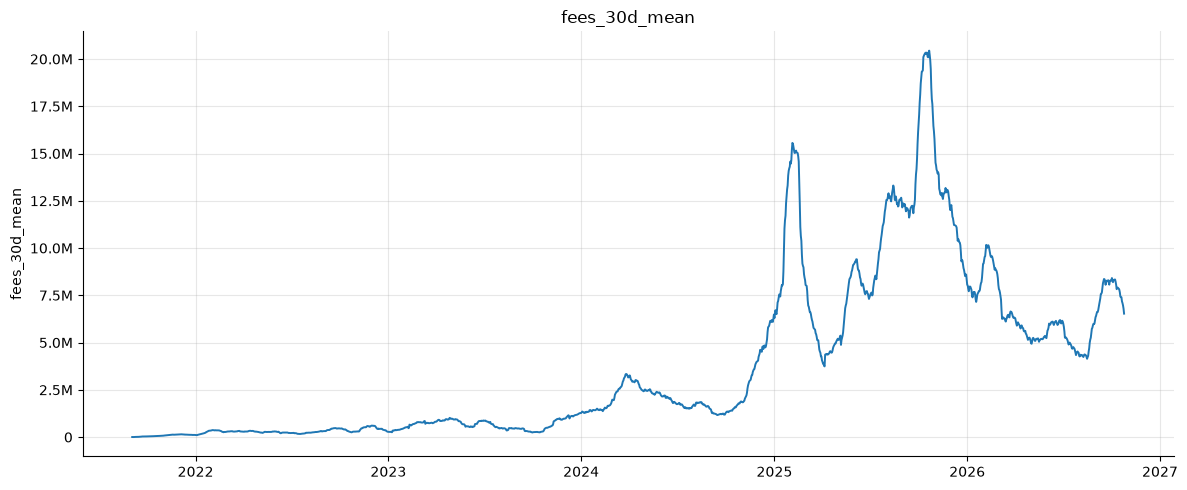

In [6]:
totals = totals.with_columns(
    perp_volume_30d_mean = pl.col("perp_volume").rolling_mean_by("date", window_size="30d"),
    fees_30d_mean = pl.col("fees").rolling_mean_by("date", window_size="30d")
)
plot_series(totals,  "fees_30d_mean")


In [7]:
import numpy as np
def fit_gbm_mle(df: pl.DataFrame, col: str, date_col: str = "date", periods_per_year: int = 365):
    s = (
        df.sort(date_col)
        .filter(pl.col(col) > 0)  # log of 0 / null is undefined
        .select(pl.col(col).log().diff().alias("r"))
        .drop_nulls()["r"]
        .to_numpy()
    )
    dt = 1 / periods_per_year
    sigma = s.std(ddof=1) / np.sqrt(dt)
    mu = s.mean() / dt + sigma**2 / 2
    return mu, sigma  # annualised


mu, sigma = fit_gbm_mle(totals, "perp_volume")

### Abstract
We may model the 30d rolling mean of both fees and trading volume as geometric brownian motion $$S_t = S_0 \exp\left(\left(\mu - \tfrac{\sigma^2}{2}\right)t + \sigma W_t\right)$$ and use an MLE estimator to find them:

In [8]:
m_fees, s_fees = fit_gbm_mle(totals, "fees_30d_mean")
m_volume, s_volume = fit_gbm_mle(totals, "perp_volume_30d_mean")
print(f"Fees: mu={m_fees:.2f}, sigma={s_fees:.2f}")
print(f"Perp Volume: mu={m_volume:.2f}, sigma={s_volume:.2f}")
average_fee_bps = totals.select("fees").sum() * 10_000 / totals.select("perp_volume").sum()
print(f"Average fee in basis points: {average_fee_bps["fees"][0]:.3f}")
average_fees = totals.select("fees").mean()
print(f"Average daily fees in dollars {average_fees["fees"][0]:.1f}")

Fees: mu=1.72, sigma=0.79
Perp Volume: mu=2.06, sigma=0.84
Average fee in basis points: 4.519
Average daily fees in dollars 3749554.8


### Our Business
DEXs pay on average 35% of the trading fees we generate. We currently have ammased 100m in volume over the last 365 days, which would be an aggregate 40_000 in fees, which if modelled exponentially would give us the function $daily\_fees\_generated_{day} = e^{0.01803\cdot day}$. We can then claim that the daily fees generated by us as a fraction of market share is $TAM_captured = daily\_fees\_generated_{day} / average\_fees = \frac{e^{0.01803\cdot\day}}{3749554}$. 

In [14]:
x = [i for i in range(60, 100)]
y = [np.exp(0.1 * i)/3749554 for i in range(60, 100)]

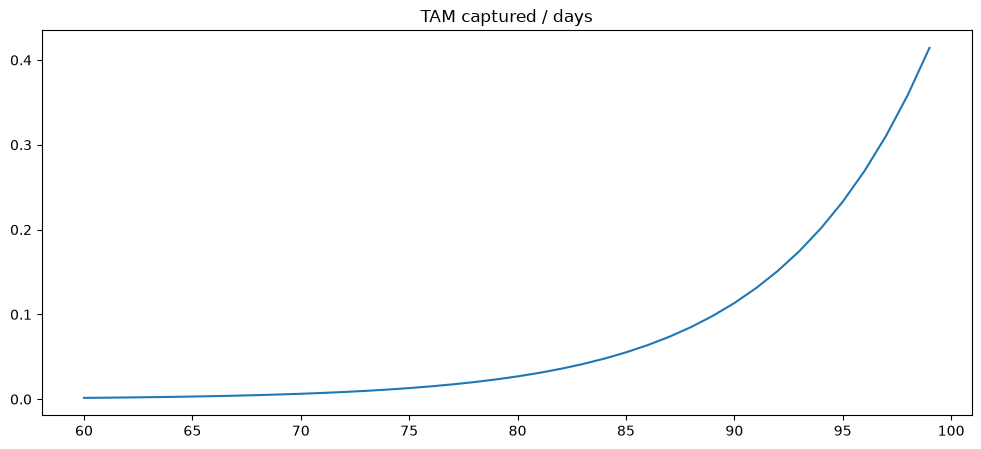

In [17]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.set_title("TAM captured / days")
ax.plot(x, y)